In [126]:
from csv import reader

In [127]:
def load_csv(filename):
	dataset = list()
	with open(filename, 'r') as Placement_Data_Full_Class:
		csv_reader = reader(Placement_Data_Full_Class)
		next(csv_reader)
		for row in csv_reader:
			if not row:
				continue
			dataset.append(row)
	return dataset

In [128]:
dataset = load_csv('Placement_Data_Full_Class.csv')

In [129]:
import pandas as pd
dataset = pd.read_csv('Placement_Data_Full_Class.csv')
dataset.head()

,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
0,1,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,Placed,270000.0
1,2,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,Placed,200000.0
2,3,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,Placed,250000.0
3,4,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,Not Placed,NaN
4,5,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,Placed,425000.0


In [130]:
dataset['status'] = dataset['status'].map({'Placed': 1, 'Not Placed': 0})
dataset.head()

,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
0,1,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,1,270000.0
1,2,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,1,200000.0
2,3,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,1,250000.0
3,4,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,0,NaN
4,5,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,1,425000.0


In [131]:
#Plotting
X=dataset[['mba_p','degree_p']].values
y=dataset['status'].values

In [132]:
#Plotting
import matplotlib.pyplot as plt
fig = plt.figure(figsize=(10,8))

<Figure size 1000x800 with 0 Axes>

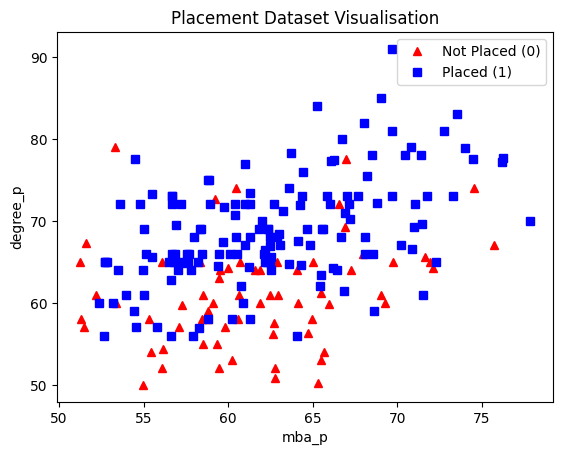

In [133]:
plt.plot(X[:, 0][y == 0], X[:, 1][y == 0], 'r^', label='Not Placed (0)')
plt.plot(X[:, 0][y == 1], X[:, 1][y == 1], 'bs', label='Placed (1)')
plt.xlabel("mba_p")
plt.ylabel("degree_p")
plt.title('Placement Dataset Visualisation')
plt.legend()
plt.show()

In [134]:
def step_func(z):
        return 1.0 if (z > 0) else 0.0

In [135]:
import numpy as np


In [136]:
def perceptron(X, y, lr, epochs):

    # X --> Inputs.
    # y --> labels/target.
    #lr --> learning rate.
    # epochs --> Number of iterations.

    # m-> number of training examples
    # n-> number of features
    m, n = X.shape

    # Initializing parapeters(theta) to zeros.
    # +1 in n+1 for the bias term.
    theta = np.zeros((n+1,1))

    # Empty list to store how many examples were
    # misclassified at every iteration.
    n_miss_list = []

    # Training.
    for epoch in range(epochs):

        # variable to store #misclassified.
        n_miss = 0

        # looping for every example.
        for idx, x_i in enumerate(X):

            # Insering 1 for bias, X0 = 1.
            x_i = np.insert(x_i, 0, 1).reshape(-1,1)

            # Calculating prediction/hypothesis.
            y_hat = step_func(np.dot(x_i.T, theta))

            # Updating if the example is misclassified.
            if (np.squeeze(y_hat) - y[idx]) != 0:
                theta += lr*((y[idx] - y_hat)*x_i)

                # Incrementing by 1.
                n_miss += 1

        # Appending number of misclassified examples
        # at every iteration.
        n_miss_list.append(n_miss)
        print(f"Epoch {epoch + 1}/{epochs} - Jumlah Salah (Errors): {n_miss}")
    return theta, n_miss_list

In [137]:
def plot_decision_boundary(X,y,theta):

    # X --> Inputs
    # theta --> parameters

    # The Line is y=mx+c
    # So, Equate mx+c = theta0.X0 + theta1.X1 + theta2.X2
    # Solving we find m and c
    x1 = [min(X[:,0]), max(X[:,0])]
    m = -theta[1]/theta[2]
    c = -theta[0]/theta[2]
    x2 = m*np.array(x1)+c

    # Plotting
    fig = plt.figure(figsize=(10,8))
    plt.plot(X[:, 0][y==0], X[:, 1][y==0], "r^")
    plt.plot(X[:, 0][y==1], X[:, 1][y==1], "bs")
    plt.plot(x1,x2,'-y',linewidth=2,label='Decision Boundary')
    plt.xlabel("mba_p")
    plt.ylabel("degree_p")
    plt.title('Perceptron Algorithm')
    plt.legend()
    plt.show()

In [138]:
theta, miss_l = perceptron(X, y, 0.01, 100)

Epoch 1/100 - Jumlah Salah (Errors): 101
Epoch 2/100 - Jumlah Salah (Errors): 88
Epoch 3/100 - Jumlah Salah (Errors): 86
Epoch 4/100 - Jumlah Salah (Errors): 86
Epoch 5/100 - Jumlah Salah (Errors): 87
Epoch 6/100 - Jumlah Salah (Errors): 82
Epoch 7/100 - Jumlah Salah (Errors): 88
Epoch 8/100 - Jumlah Salah (Errors): 91
Epoch 9/100 - Jumlah Salah (Errors): 80
Epoch 10/100 - Jumlah Salah (Errors): 87
Epoch 11/100 - Jumlah Salah (Errors): 80
Epoch 12/100 - Jumlah Salah (Errors): 82
Epoch 13/100 - Jumlah Salah (Errors): 78
Epoch 14/100 - Jumlah Salah (Errors): 84
Epoch 15/100 - Jumlah Salah (Errors): 88
Epoch 16/100 - Jumlah Salah (Errors): 88
Epoch 17/100 - Jumlah Salah (Errors): 84
Epoch 18/100 - Jumlah Salah (Errors): 87
Epoch 19/100 - Jumlah Salah (Errors): 80
Epoch 20/100 - Jumlah Salah (Errors): 78
Epoch 21/100 - Jumlah Salah (Errors): 85
Epoch 22/100 - Jumlah Salah (Errors): 80
Epoch 23/100 - Jumlah Salah (Errors): 78
Epoch 24/100 - Jumlah Salah (Errors): 85
Epoch 25/100 - Jumlah Sa

In [139]:
def predict(X,theta):
  X_bias=np.c_[np.ones((X.shape[0],1)),X]
  y_pred = [1 if z > 0 else 0 for z in np.dot(X_bias, theta)]
  return np.array(y_pred)

y_pred=predict(X,theta)

accuracy=np.mean(y_pred.flatten()==y)*100
print(f"akurasi perceptron:{accuracy:.2f}%")

akurasi perceptron:75.81%


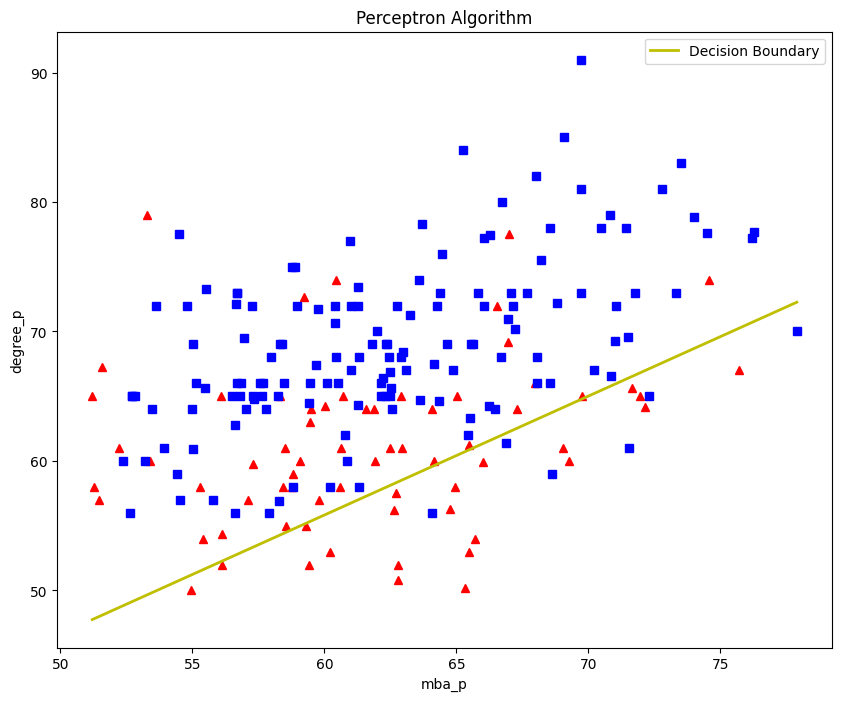

In [140]:
plot_decision_boundary(X,y,theta)

In [141]:
from sklearn.metrics import classification_report, confusion_matrix

print("Confusion Matrix:")
print(confusion_matrix(y, y_pred))

print("\nReport Klasifikasi Detail:")
print(classification_report(y, y_pred))

Confusion Matrix:
[[ 21  46]
 [  6 142]]

Report Klasifikasi Detail:
              precision    recall  f1-score   support

           0       0.78      0.31      0.45        67
           1       0.76      0.96      0.85       148

    accuracy                           0.76       215
   macro avg       0.77      0.64      0.65       215
weighted avg       0.76      0.76      0.72       215

